# Patient Timeline (LifeLines-style record overview)

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

Lays out one patient's record (encounters, diagnoses, medications and a key lab value) as parallel swimlanes on a shared time axis. Cause and effect that a chronological list buries become visible: a drug started after a diagnosis, a lab value that improved, an admission that followed a gap in treatment.

## When to use

- Review a single patient's history at a glance (case review, care coordination, clinical teaching)
- Show how treatments line up with diagnoses, admissions and lab trends
- Show any entity's event history across several kinds of event (customer, asset, account)

## Avoid when

- Comparing many patients (use a swimmer plot or lasagna plot)
- The record has hundreds of events in a short period (aggregate or zoom first)
- Exact values matter more than sequence (use a table)

## Alternatives

- Swimmer plot
- Gantt chart
- Lab reference-range small multiples

## Design tips

- Keep one shared time axis and one lane per kind of event
- Use bars for things with duration (stays, prescriptions) and markers for instants (diagnoses, visits)
- Draw the lab reference range as a band so out-of-range periods stand out
- Use de-identified data (shift dates, drop identifiers); executed notebooks store their outputs

## Example

A simulated patient over 18 months: type 2 diabetes and hypertension diagnoses, three medications started and adjusted, one hospital admission and outpatient visits, and HbA1c measured every few months.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import matplotlib.dates as mdates

### Data

In [2]:
start = pd.Timestamp("2024-01-01")
day = lambda d: start + pd.Timedelta(days=d)
encounters = pd.DataFrame([
    ("Outpatient visit", day(0), day(1)), ("Outpatient visit", day(95), day(96)),
    ("Outpatient visit", day(190), day(191)), ("Emergency visit", day(296), day(297)),
    ("Hospital admission", day(297), day(303)), ("Outpatient visit", day(320), day(321)),
    ("Outpatient visit", day(420), day(421)), ("Outpatient visit", day(520), day(521)),
], columns=["kind", "start", "end"])
diagnoses = pd.DataFrame([
    ("Type 2 diabetes", day(0)), ("Hypertension", day(95)),
    ("Hyperglycaemia", day(297)), ("Diabetic neuropathy", day(420)),
], columns=["diagnosis", "date"])
medications = pd.DataFrame([
    ("Metformin", day(5), day(240)), ("Metformin", day(310), day(545)),
    ("Lisinopril", day(100), day(545)),
    ("Empagliflozin", day(330), day(545)),
    ("Insulin (short course)", day(297), day(330)),
], columns=["drug", "start", "end"])
rng = np.random.default_rng(400)
lab_days = [0, 45, 95, 150, 190, 250, 297, 320, 370, 420, 470, 520]
true = [9.1, 8.4, 7.6, 7.1, 6.9, 7.8, 9.4, 8.2, 7.3, 6.8, 6.6, 6.5]
hba1c = pd.DataFrame({"date": [day(d) for d in lab_days],
                      "hba1c": np.round(np.array(true) + rng.normal(0, 0.1, len(true)), 1)})
target = (4.0, 7.0)   # HbA1c target band (%)
hba1c.head()

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_55419/3545792776.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  day = lambda d: start + pd.Timedelta(days=d)


,date,hba1c
0,2024-01-01,9.0
1,2024-02-15,8.2
2,2024-04-05,7.8
3,2024-05-30,7.1
4,2024-07-09,6.8


### Plot

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_55419/3545792776.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  day = lambda d: start + pd.Timedelta(days=d)


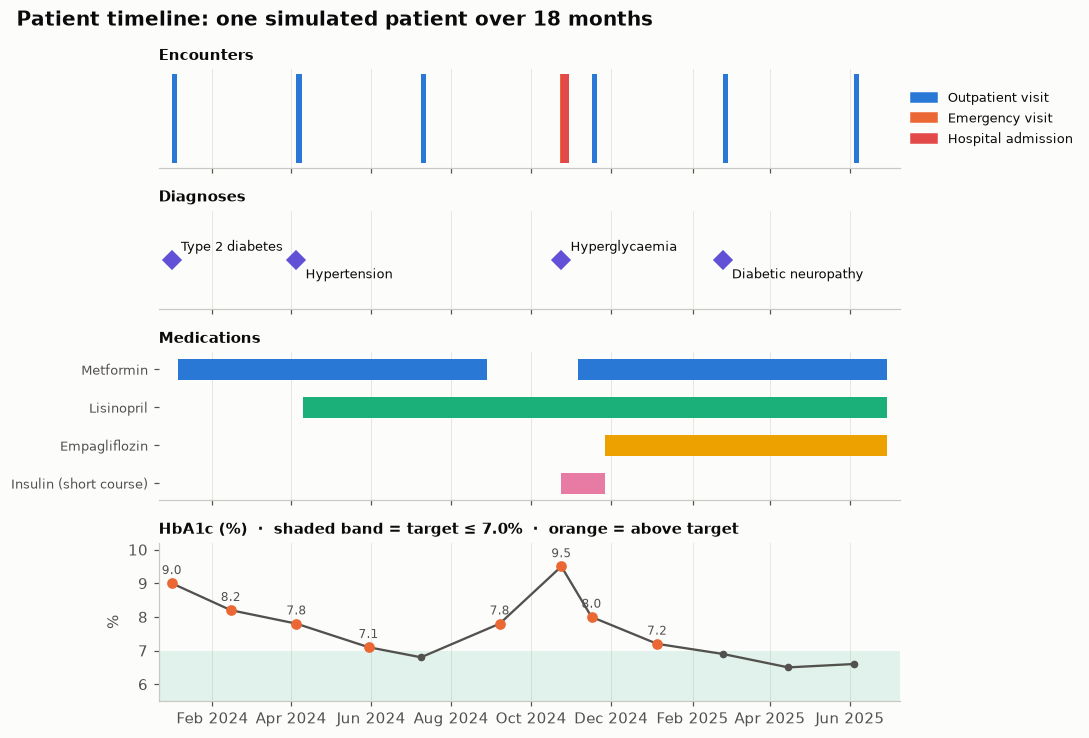

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(10, 6.8), sharex=True, height_ratios=[1, 1, 1.5, 1.6])
ax_enc, ax_dx, ax_med, ax_lab = axes
enc_colors = {"Outpatient visit": PALETTE[0], "Emergency visit": PALETTE[1], "Hospital admission": PALETTE[7]}
for _, r in encounters.iterrows():
    width = max((r["end"] - r["start"]).days, 4)
    ax_enc.barh(0, width, left=r["start"], height=0.55, color=enc_colors[r["kind"]])
ax_enc.set_yticks([])
ax_enc.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in enc_colors.items()],
              loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8.5)
ax_enc.set_title("Encounters", fontsize=10, loc="left")

for i, (_, r) in enumerate(diagnoses.iterrows()):
    ax_dx.plot(r["date"], 0, "D", color=PALETTE[6], markersize=8)
    ax_dx.annotate(r["diagnosis"], (r["date"], 0), xytext=(6, 6 if i % 2 == 0 else -12),
                   textcoords="offset points", fontsize=8.5, color="#0b0b0b")
ax_dx.set_ylim(-1, 1)
ax_dx.set_yticks([])
ax_dx.set_title("Diagnoses", fontsize=10, loc="left")

drugs = list(dict.fromkeys(medications["drug"]))
for _, r in medications.iterrows():
    k = drugs.index(r["drug"])
    ax_med.barh(k, (r["end"] - r["start"]).days, left=r["start"], height=0.55, color=PALETTE[[0, 2, 3, 4][k]])
ax_med.set_yticks(range(len(drugs)), drugs, fontsize=8.5)
ax_med.invert_yaxis()
ax_med.set_title("Medications", fontsize=10, loc="left")

ax_lab.axhspan(*target, color=PALETTE[2], alpha=0.12, linewidth=0)
ax_lab.plot(hba1c["date"], hba1c["hba1c"], "-o", color="#52514e", markersize=4, linewidth=1.5)
high = hba1c["hba1c"] > target[1]
ax_lab.plot(hba1c.loc[high, "date"], hba1c.loc[high, "hba1c"], "o", color=PALETTE[1], markersize=6)
for _, r in hba1c[high].iterrows():
    ax_lab.annotate(f"{r['hba1c']:.1f}", (r["date"], r["hba1c"]), xytext=(0, 6),
                    textcoords="offset points", ha="center", fontsize=8, color="#52514e")
ax_lab.set_ylim(5.5, 10.2)
ax_lab.set_ylabel("%")
ax_lab.set_title("HbA1c (%)  ·  shaded band = target ≤ 7.0%  ·  orange = above target", fontsize=10, loc="left")
ax_lab.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_lab.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.set_xlim(day(-10), day(555))
for ax in axes[:3]:
    ax.spines["left"].set_visible(False)
fig.suptitle("Patient timeline: one simulated patient over 18 months", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

The HbA1c lane shows the effect of treatment. It falls into the target band (≤ 7.0%) about six months after metformin starts, and again after empagliflozin is added in month 11. The admission in month 10 follows a gap in metformin, visible as a break in its bar.

## Reference

This method comes from the research literature:

- Plaisant, C., Milash, B., Rose, A., Widoff, S. & Shneiderman, B. (1996). LifeLines: visualizing personal histories. Proceedings of the ACM CHI Conference on Human Factors in Computing Systems (CHI '96), 221–227. <https://doi.org/10.1145/238386.238493>

---
Standalone script: [`patient_timeline.py`](patient_timeline.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)